# Алгоритм k Ближайших Соседей (K-nearest neighbors, k-NN)

K-NN - это алгоритм машинного обучения, используемый для классификации и регрессии. Он основан на принципе, что объекты, похожие друг на друга, вероятно, принадлежат к одному классу. 

Импортируйте необходимые библиотеки:

Импортируйте библиотеки numpy и pandas для работы с данными.
Импортируйте классы KNeighborsClassifier и train_test_split из библиотеки sklearn.
Импортируйте метрики для оценки качества классификации.
Загрузите данные Iris:

Воспользуйтесь функцией load_iris() из модуля sklearn.datasets, чтобы загрузить набор данных Iris.
Разделите данные на обучающую и тестовую выборки:

Используйте функцию train_test_split для разделения данных на обучающую и тестовую выборки (например, 80% для обучения и 20% для тестирования).
Подберите k и обучите модель KNN:

Подберите наилучший гиперпараметр k.
Обучите модель на обучающей выборке с помощью метода fit().
Сделайте предсказания и оцените модель:

Сделайте предсказания классов для тестовой выборки с помощью метода predict().
Оцените точность модели с помощью метрик.
Проанализируйте полученные результаты

ЗАДАНИЕ 1

Подгрузка библиотек и данных

In [169]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris

# Загрузите набор данных Iris
iris = load_iris()

X = iris.data
Y = iris.target

# форматирование в DataFrame
df = pd.DataFrame(X, columns=iris.feature_names)
df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


Разделение данных на тестовую и обучающую выборки

In [170]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2)

Стандартизация признаков

In [178]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

Выбор оптимального значения к

In [179]:
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [180]:
k_range = range(1, 31)
k_scores = []

In [181]:
for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, Y_train, cv=5, scoring='accuracy')
    k_scores.append(scores.mean())

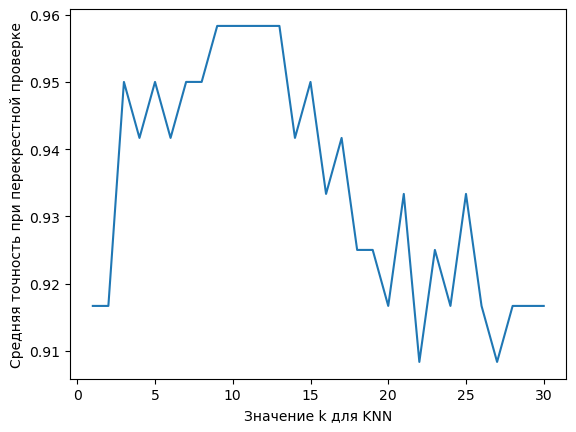

In [182]:
plt.plot(k_range, k_scores)
plt.xlabel('Значение k для KNN')
plt.ylabel('Средняя точность при перекрестной проверке')
plt.show()

In [184]:
optimal_k = k_scores.index(max(k_scores)) + 1
print(f"Оптимальное значение k: {optimal_k}")

knn = KNeighborsClassifier(n_neighbors=optimal_k)
knn.fit(X_train, Y_train)
Y_pred = knn.predict(X_test)

Оптимальное значение k: 9


Построение и обучение модели

In [118]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=9)
knn.fit(X_train, Y_train)

,n_neighbors,9
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


Прогнозирование (предсказания) на тестовых данных

In [119]:
Y_pred = knn.predict(X_test)

In [120]:
pd.DataFrame({
    'Предсказание': Y_pred,
    'Истинные': Y_test
})

,Предсказание,Истинные
0,0,0
1,2,2
2,0,0
3,0,0
4,1,1
5,2,2
6,1,1
7,1,1
8,2,2
9,2,2


In [121]:
pd.crosstab(Y_test, Y_pred, rownames=['Истинные'], colnames=['Предсказание'], margins=True)

Предсказание,0,1,2,All
Истинные,,,,
0,9,0,0,9
1,0,8,0,8
2,0,1,12,13
All,9,9,12,30


Оценка модели

In [122]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
accuracy = accuracy_score(Y_test, Y_pred)
precision = precision_score(Y_test, Y_pred, average='weighted')
recall = recall_score(Y_test, Y_pred, average='weighted')

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)

Accuracy: 0.9666666666666667
Precision: 0.9703703703703703
Recall: 0.9666666666666667


Вывод: Полученная модель описывает 97% данных, что говорит о ее высокой точности, выбор параметра k является верным. к = 9 - оптимальный параметр.

ЗАДАНИЕ 2

Необходимо применить метод ближайших соседей (KNN) для прогнозирования средней рыночной цены автомобиля MMRCurrentRetailAveragePrice для новых автомобилей в тестовой выборке.

Подгрузка данных

In [186]:
import pandas as pd
train_df = pd.read_csv('train_df.csv')
# тестовая выборка
test_df = pd.read_csv('test_df.csv')

train_z = train_df.select_dtypes(exclude=object)
test_z = test_df.select_dtypes(exclude=object)

x_train = train_z.drop("MMRCurrentRetailAveragePrice", axis=1)
y_train = train_z["MMRCurrentRetailAveragePrice"]
x_test = test_z.drop("MMRCurrentRetailAveragePrice", axis=1).copy()
y_test = test_z["MMRCurrentRetailAveragePrice"]

In [187]:
train_df.describe()

,Unnamed: 0,RefId,IsBadBuy,VehYear,VehicleAge,WheelTypeID,VehOdo,MMRAcquisitionAuctionAveragePrice,MMRAcquisitionAuctionCleanPrice,MMRAcquisitionRetailAveragePrice,MMRAcquisitonRetailCleanPrice,MMRCurrentAuctionAveragePrice,MMRCurrentAuctionCleanPrice,MMRCurrentRetailAveragePrice,MMRCurrentRetailCleanPrice,BYRNO,VNZIP1,VehBCost,IsOnlineSale,WarrantyCost
count,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000,1663.000000
mean,16028.836440,16040.542393,0.030667,2005.391461,4.608539,1.501503,77553.016236,5591.322309,6796.396873,9017.541191,10325.905592,6036.748647,7368.968130,9333.098016,10774.956103,26218.734215,55298.568250,6556.914011,0.057727,1308.187613
std,10347.047933,10353.403473,0.172467,1.889893,1.889893,0.522506,15421.749930,2475.350960,2706.119165,2986.534864,3206.207672,2547.043036,2794.760835,2876.742771,3110.794911,22472.786188,25582.874664,1920.578458,0.233297,594.799123
min,275.000000,276.000000,0.000000,2001.000000,1.000000,1.000000,24805.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,835.000000,17406.000000,2010.000000,0.000000,462.000000
25%,6150.000000,6157.000000,0.000000,2004.000000,3.000000,1.000000,68149.000000,3616.500000,4677.000000,6754.000000,7976.500000,3922.000000,5133.500000,7094.500000,8408.500000,17212.000000,29984.500000,5000.000000,0.000000,853.000000
50%,14428.000000,14438.000000,0.000000,2006.000000,4.000000,1.000000,78564.000000,5398.000000,6632.000000,8920.000000,10202.000000,5805.000000,7186.000000,9119.000000,10492.000000,20740.000000,50111.000000,6400.000000,0.000000,1215.000000
75%,24840.500000,24858.500000,0.000000,2007.000000,6.000000,2.000000,88361.500000,7404.000000,8627.500000,10981.500000,12418.000000,7799.000000,9258.000000,11375.000000,12901.500000,25100.000000,80022.000000,7935.000000,0.000000,1641.000000
max,34801.000000,34824.000000,1.000000,2009.000000,9.000000,3.000000,115026.000000,20001.000000,22705.000000,24730.000000,27267.000000,18677.000000,21046.000000,23450.000000,25577.000000,99761.000000,97402.000000,12525.000000,1.000000,5613.000000


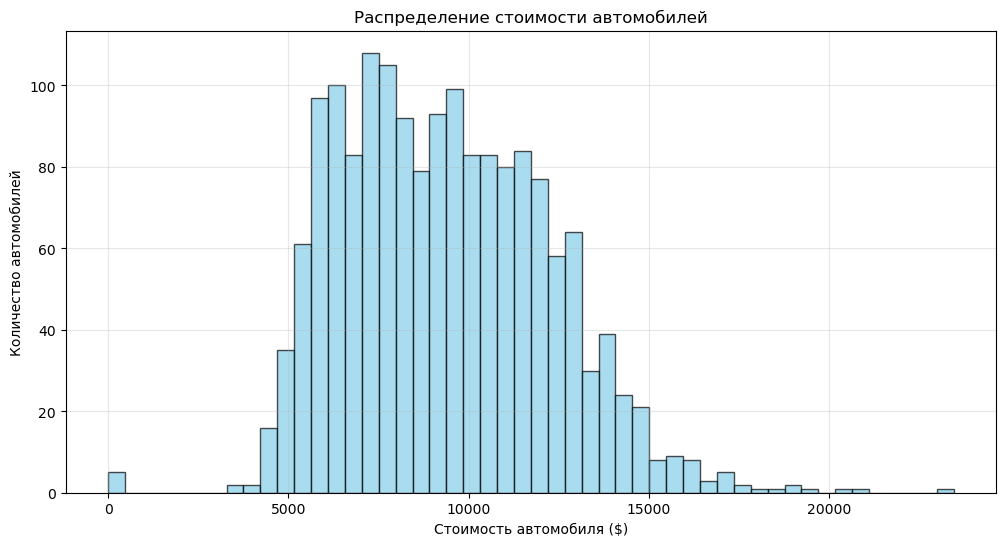

In [188]:
plt.figure(figsize=(12, 6))
plt.hist(y_train, bins=50, alpha=0.7, color='skyblue', edgecolor='black')
plt.xlabel('Стоимость автомобиля ($)')
plt.ylabel('Количество автомобилей')
plt.title('Распределение стоимости автомобилей')
plt.grid(True, alpha=0.3)
plt.show()

In [189]:
print("Train shape:", x_train.shape)
print("Test shape:", y_train.shape)
print("Columns:", train_df.columns.tolist())

Train shape: (1663, 19)
Test shape: (1663,)
Columns: ['Unnamed: 0', 'RefId', 'IsBadBuy', 'PurchDate', 'Auction', 'VehYear', 'VehicleAge', 'Make', 'Model', 'Trim', 'SubModel', 'Color', 'Transmission', 'WheelTypeID', 'WheelType', 'VehOdo', 'Nationality', 'Size', 'TopThreeAmericanName', 'MMRAcquisitionAuctionAveragePrice', 'MMRAcquisitionAuctionCleanPrice', 'MMRAcquisitionRetailAveragePrice', 'MMRAcquisitonRetailCleanPrice', 'MMRCurrentAuctionAveragePrice', 'MMRCurrentAuctionCleanPrice', 'MMRCurrentRetailAveragePrice', 'MMRCurrentRetailCleanPrice', 'PRIMEUNIT', 'AUCGUART', 'BYRNO', 'VNZIP1', 'VNST', 'VehBCost', 'IsOnlineSale', 'WarrantyCost']


Стандартизация признаков

In [190]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

Выбор оптимального значения к

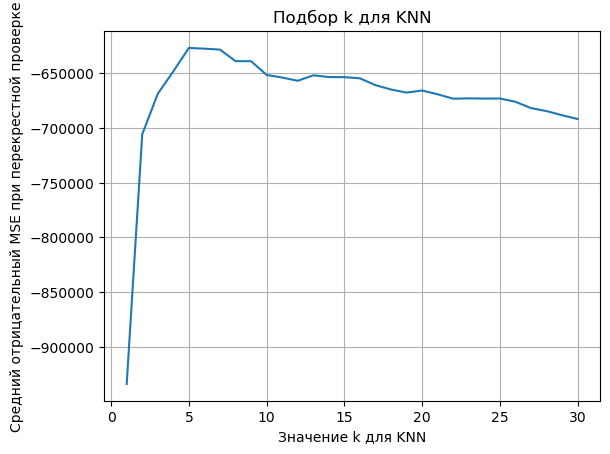

In [197]:
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsRegressor
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings("ignore")

k_range = range(1, 31)
k_scores = []

for k in k_range:
    knn = KNeighborsRegressor(n_neighbors=k)
    scores = cross_val_score(knn, x_train, y_train, cv=5, scoring='neg_mean_squared_error')
    k_scores.append(scores.mean())

plt.plot(k_range, k_scores)
plt.xlabel('Значение k для KNN')
plt.ylabel('Средний отрицательный MSE при перекрестной проверке')
plt.title('Подбор k для KNN')
plt.grid(True)
plt.show()

In [198]:
optimal_k = k_range[np.argmax(k_scores)]  # +1 не нужно, так как k_range начинается с 1
print(f"Оптимальное значение k: {optimal_k}")
knn = KNeighborsRegressor(n_neighbors=optimal_k)
knn.fit(x_train, y_train)
y_pred = knn.predict(x_test)

Оптимальное значение k: 5


Построение и обучение модели

In [193]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
knn = KNeighborsRegressor(n_neighbors=5)
knn.fit(x_train, y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


Прогнозирование(предсказания) данных на основе тестовой выборки

In [194]:
pd.DataFrame({
    'Предсказание': y_pred,
    'Истинные': y_test
})

,Предсказание,Истинные
0,8939.4,8875.0
1,10704.2,10541.0
2,10017.4,10206.0
3,8397.8,9899.0
4,14332.4,14552.0
...,...,...
1492,8983.6,9782.0
1493,7243.6,7286.0
1494,8343.2,8154.0
1495,12120.0,12685.0


In [196]:
pd.crosstab(y_test, y_pred, rownames=['Истинные'], colnames=['Предсказание'], margins=True)

Предсказание,4062.6,4151.4,4995.4,5026.2,5076.4,5090.8,5180.4,5187.8,5258.8,5259.8,...,16562.4,16732.4,16983.6,17061.6,17237.0,17262.4,17279.2,17341.4,19941.2,All
Истинные,,,,,,,,,,,,,,,,,,,,,
0.0,1,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,4
3242.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
3541.0,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,1
3895.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
4143.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20469.0,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
20551.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1
20609.0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,1


Оценка модели

In [195]:
print("МЕТРИКИ РЕГРЕССИИ")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2:", r2_score(y_test, y_pred))

МЕТРИКИ РЕГРЕССИИ
MAE: 573.267735470942
MSE: 666641.3754175017
R2: 0.9264640009981849


Вывод: Полученная модель описывает 93% изначальный данных, что говорит о ее высокой точности. Оптимальный выбранный параметр к = 5.